In [1]:
import h5py
import os
PCAM_DIR = os.path.join("..", "..", "Data", "PatchCamelyon")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

def print_h5_structure(g, prefix=""):
    for key in g.keys():
        item = g[key]
        if isinstance(item, h5py.Dataset):
            print(f"{prefix}/{key} : Dataset, shape={item.shape}, dtype={item.dtype}")
        elif isinstance(item, h5py.Group):
            print(f"{prefix}/{key} : Group")
            print_h5_structure(item, prefix + "/" + key)

def show_images_grid(images, labels, dataset_name, max_images=9):
    num_images = min(max_images, images.shape[0])
    cols = math.ceil(math.sqrt(num_images))
    rows = math.ceil(num_images / cols)

    plt.figure(figsize=(cols * 3, rows * 3))
    for idx in range(num_images):
        img = images[idx]
        label = labels[idx]
        plt.subplot(rows, cols, idx + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray')
        else:
            if img.shape[-1] == 1:
                img = np.squeeze(img, axis=-1)
                plt.imshow(img, cmap='gray')
            else:
                plt.imshow(img)
        plt.axis('off')
        plt.title(f"Label: {label}")
    plt.suptitle(dataset_name)
    plt.tight_layout()
    plt.show()

In [2]:
train_df = pd.read_csv(os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_meta.csv"))

print(train_df["wsi"].nunique())
print(train_df["wsi"].value_counts()[:90])

216
wsi
camelyon16_train_tumor_093     3800
camelyon16_train_tumor_098     3695
camelyon16_train_tumor_094     3581
camelyon16_train_tumor_087     3238
camelyon16_train_tumor_004     3217
                               ... 
camelyon16_train_tumor_018      942
camelyon16_train_tumor_067      822
camelyon16_train_normal_062     799
camelyon16_train_normal_073     792
camelyon16_train_normal_034     788
Name: count, Length: 90, dtype: int64


In [3]:
train_df["set"] = train_df["wsi"].astype(str).str[11:-4]

In [4]:
train_df["set"]

0          train_tumor
1          train_tumor
2          train_tumor
3          train_tumor
4         train_normal
              ...     
262139     train_tumor
262140     train_tumor
262141     train_tumor
262142    train_normal
262143     train_tumor
Name: set, Length: 262144, dtype: object

In [5]:
train_df["set"].value_counts()

set
train_tumor     179720
train_normal     82424
Name: count, dtype: int64

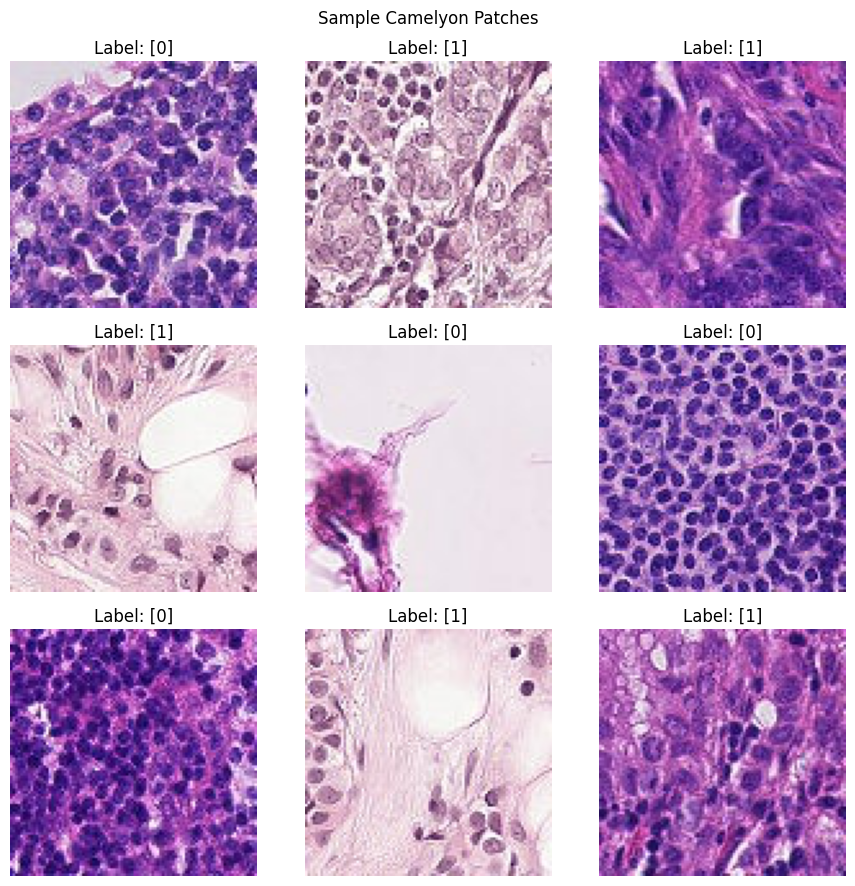

In [6]:
max_images = 9
train_images = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_x.h5")
train_labels = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_y.h5")

with h5py.File(train_images, 'r') as img_f, h5py.File(train_labels, 'r') as lbl_f:
    images = img_f["x"][()]
    labels = lbl_f["y"][()]
    num_images = min(max_images, images.shape[0])
    cols = math.ceil(math.sqrt(num_images))
    rows = math.ceil(num_images / cols)

    plt.figure(figsize=(cols * 3, rows * 3))
    for idx in range(num_images):
        img = images[idx]
        label = labels[idx]
        plt.subplot(rows, cols, idx + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray')
        else:
            if img.shape[-1] == 1:
                img = np.squeeze(img, axis=-1)
                plt.imshow(img, cmap='gray')
            else:
                plt.imshow(img)
        plt.axis('off')
        plt.title(f"Label: {label[0][0]}")
    plt.suptitle("Sample Camelyon Patches")
    plt.tight_layout()
    plt.show()

In [7]:
import h5py
import pandas as pd
import numpy as np
from PIL import Image
import os
from tqdm import tqdm

# --- PARAMETERS ---
images_path = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_x.h5")
meta_path = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_meta.csv")
output_dir = os.path.join(PCAM_DIR, "train_images_sampled")
n_most_populous = 50      # Number of most populous WSIs to include
sample_percent = 0.25     # Percent of patches per class per WSI to sample (e.g. 0.1 for 10%)
random_seed = 42          # For reproducibility

os.makedirs(output_dir, exist_ok=True)

meta = pd.read_csv(meta_path)
meta['tumor_patch'] = meta['tumor_patch'].apply(lambda x: "TRUE" if x in [1, True, "TRUE", "True", "true"] else "FALSE")

wsi_counts = meta['wsi'].value_counts()
top_wsis = wsi_counts.nlargest(n_most_populous).index.tolist()

np.random.seed(random_seed)

sampled_h5_indices = []
wsi_sample_counts = {}
class_sample_counts = {"TRUE": 0, "FALSE": 0}

for wsi in top_wsis:
    wsi_df = meta[meta['wsi'] == wsi]
    true_indices = wsi_df[wsi_df['tumor_patch'] == "TRUE"]["index"].to_numpy()
    false_indices = wsi_df[wsi_df['tumor_patch'] == "FALSE"]["index"].to_numpy()
    
    # Minimum class count for balancing
    n_true = len(true_indices)
    n_false = len(false_indices)
    if n_true == 0 or n_false == 0:
        # Skip WSI if one class is missing
        print(f"Skipping {wsi}: class missing (TRUE={n_true}, FALSE={n_false})")
        continue
    # Calculate how many to sample per class, limited by sample_percent and minimum class count
    n_per_class = int(min(n_true, n_false, round(sample_percent * min(n_true, n_false))))
    if n_per_class < 1:
        print(f"Skipping {wsi}: not enough samples in both classes after percent calculation.")
        continue
    sampled_true = np.random.choice(true_indices, size=n_per_class, replace=False)
    sampled_false = np.random.choice(false_indices, size=n_per_class, replace=False)
    sampled_h5_indices.extend(sampled_true.tolist() + sampled_false.tolist())
    wsi_sample_counts[wsi] = 2 * n_per_class
    class_sample_counts["TRUE"] += n_per_class
    class_sample_counts["FALSE"] += n_per_class

print("\nSampled (balanced) patches per WSI:")
for wsi, count in wsi_sample_counts.items():
    print(f"  {wsi}: {count} patches (TRUE: {count//2}, FALSE: {count//2})")

print(f"\nTotal patches sampled: {len(sampled_h5_indices)}")
print(f"  TRUE: {class_sample_counts['TRUE']}")
print(f"  FALSE: {class_sample_counts['FALSE']}")

with h5py.File(images_path, 'r') as img_f:
    images = img_f["x"]
    for h5_idx in tqdm(sampled_h5_indices, desc="Saving sampled images"):
        row = meta.loc[meta["index"] == h5_idx].iloc[0]
        wsi = row["wsi"].replace("camelyon16_train_", "")
        class_val = row["tumor_patch"]
        filename = f"{wsi}_{h5_idx}_{class_val}.png"
        save_path = os.path.join(output_dir, filename)

        img_arr = images[h5_idx]
        if img_arr.ndim == 2:
            img = Image.fromarray(np.uint8(img_arr))
        else:
            if img_arr.shape[-1] == 1:
                img_arr = np.squeeze(img_arr, axis=-1)
                img = Image.fromarray(np.uint8(img_arr))
            else:
                img = Image.fromarray(np.uint8(img_arr))
        img.save(save_path)

print("Export complete!")

Skipping camelyon16_train_tumor_095: class missing (TRUE=2379, FALSE=0)
Skipping camelyon16_train_tumor_092: class missing (TRUE=2296, FALSE=0)
Skipping camelyon16_train_tumor_054: class missing (TRUE=2122, FALSE=0)
Skipping camelyon16_train_tumor_044: class missing (TRUE=2060, FALSE=0)

Sampled (balanced) patches per WSI:
  camelyon16_train_tumor_093: 326 patches (TRUE: 163, FALSE: 163)
  camelyon16_train_tumor_098: 284 patches (TRUE: 142, FALSE: 142)
  camelyon16_train_tumor_094: 336 patches (TRUE: 168, FALSE: 168)
  camelyon16_train_tumor_087: 284 patches (TRUE: 142, FALSE: 142)
  camelyon16_train_tumor_004: 348 patches (TRUE: 174, FALSE: 174)
  camelyon16_train_tumor_096: 328 patches (TRUE: 164, FALSE: 164)
  camelyon16_train_tumor_105: 320 patches (TRUE: 160, FALSE: 160)
  camelyon16_train_tumor_061: 354 patches (TRUE: 177, FALSE: 177)
  camelyon16_train_tumor_103: 344 patches (TRUE: 172, FALSE: 172)
  camelyon16_train_tumor_107: 276 patches (TRUE: 138, FALSE: 138)
  camelyon16_tr

Saving sampled images: 100%|██████████| 15482/15482 [00:29<00:00, 522.91it/s]

Export complete!


In [8]:
# import h5py
# import pandas as pd
# import numpy as np
# from PIL import Image
# import os
# from tqdm import tqdm

# # --- PARAMETERS ---
# images_path = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_x.h5")
# meta_path = os.path.join(PCAM_DIR, "images", "camelyonpatch_level_2_split_train_meta.csv")
# output_dir = os.path.join(PCAM_DIR, "train_images_sampled")
# n_most_populous = 50       # Total number of WSIs (will split evenly between tumor/normal)
# sample_percent = 0.5       # Percent of patches per WSI to sample (e.g. 0.1 for 10%)
# random_seed = 42           # For reproducibility

# os.makedirs(output_dir, exist_ok=True)

# meta = pd.read_csv(meta_path)
# meta["set"] = np.where(
#     meta["wsi"].astype(str).str.contains("normal", case=False), "normal", "tumor"
# )
# meta['tumor_patch'] = meta['tumor_patch'].apply(lambda x: "TRUE" if x in [1, True, "TRUE", "True", "true"] else "FALSE")

# # Select top n/2 tumor and n/2 normal WSIs
# n_tumor = int(n_most_populous * 0.8)
# n_normal = n_most_populous - n_tumor
# tumor_wsis = meta[meta["set"].str.startswith("tumor")]["wsi"].value_counts().nlargest(n_tumor).index.tolist()
# normal_wsis = meta[meta["set"].str.startswith("normal")]["wsi"].value_counts().nlargest(n_normal).index.tolist()
# selected_wsis = tumor_wsis + normal_wsis

# # For each selected WSI, compute sample size (floor for minimum per-WSI), then use the lowest value across all for equality
# wsi_sample_counts = {}
# for wsi in selected_wsis:
#     wsi_patch_count = (meta["wsi"] == wsi).sum()
#     wsi_sample_counts[wsi] = int(np.floor(wsi_patch_count * sample_percent))
# min_wsi_patches = max(1, min(wsi_sample_counts.values()))  # always at least 1

# print(f"\nSelected {len(tumor_wsis)} tumor WSIs and {len(normal_wsis)} normal WSIs.")
# print(f"Sampling {min_wsi_patches} patches per WSI for {len(selected_wsis)} WSIs (set by min sample size).")

# np.random.seed(random_seed)

# sampled_h5_indices = []
# per_type_patch_count = {"tumor": 0, "normal": 0}
# for wsi in selected_wsis:
#     wsi_df = meta[meta["wsi"] == wsi].copy()
#     wsi_type = "tumor" if wsi in tumor_wsis else "normal"
#     n_patches = min_wsi_patches
#     class_counts = wsi_df['tumor_patch'].value_counts()
#     # Stratified by class
#     class_samples = {}
#     for label in class_counts.index:
#         class_samples[label] = int(round(class_counts[label] / class_counts.sum() * n_patches))
#     # Adjust rounding to match n_patches
#     total_samples = sum(class_samples.values())
#     while total_samples > n_patches:
#         label = max(class_samples, key=class_samples.get)
#         class_samples[label] -= 1
#         total_samples -= 1
#     while total_samples < n_patches:
#         label = max(class_samples, key=class_samples.get)
#         class_samples[label] += 1
#         total_samples += 1

#     # Sample the patches for this WSI
#     indices = []
#     for label, count in class_samples.items():
#         subset = wsi_df[wsi_df["tumor_patch"] == label]
#         if len(subset) <= count:
#             indices += subset["index"].tolist()
#         else:
#             indices += subset.sample(n=count, random_state=random_seed)["index"].tolist()
#     sampled_h5_indices.extend(indices)
#     per_type_patch_count[wsi_type] += len(indices)

# print(f"\nNumber of patches being saved:")
# print(f"  Tumor patches: {per_type_patch_count['tumor']}")
# print(f"  Normal patches: {per_type_patch_count['normal']}")
# print(f"  Patches per WSI: {min_wsi_patches}")
# print(f"  Total patches: {len(sampled_h5_indices)}")

# with h5py.File(images_path, 'r') as img_f:
#     images = img_f["x"]
#     for h5_idx in tqdm(sampled_h5_indices, desc="Saving sampled images"):
#         row = meta.loc[meta["index"] == h5_idx].iloc[0]
#         wsi = row["wsi"].replace("camelyon16_train_", "")
#         class_val = row["tumor_patch"]
#         filename = f"{wsi}_{h5_idx}_{class_val}.png"
#         save_path = os.path.join(output_dir, filename)

#         img_arr = images[h5_idx]
#         if img_arr.ndim == 2:
#             img = Image.fromarray(np.uint8(img_arr))
#         else:
#             if img_arr.shape[-1] == 1:
#                 img_arr = np.squeeze(img_arr, axis=-1)
#                 img = Image.fromarray(np.uint8(img_arr))
#             else:
#                 img = Image.fromarray(np.uint8(img_arr))
#         img.save(save_path)

# print("Export complete!")